# Verification — Gardner et al. (2000) toggle switch: both stable branches and the saddle over the alpha_2 scan

This notebook checks the steady states of `genetic_switch_gardner2000.bngl`, the primary
file, over the alpha_2 range of its own bifurcation scan (100 linearly spaced values from 1 to
500, at alpha_1 = 156.25, beta = 2.5, gamma = 1). `verify_gardner2000.ipynb` is the entry
point for the folder. Its scan check follows the file's own protocol, which starts every scan
point from the v-dominant state the bistability demonstration ends in, so it only ever sees
the branch reached from that one start. Here both stable branches are checked at every scan
point where they exist, together with the unstable root between them.

**The reference is exact.** A fixed point of Box 1, Eq. 1,

* du/dt = alpha_1 / (1 + v^beta) - k_deg u,  dv/dt = alpha_2 / (1 + u^gamma) - k_deg v,

has v = alpha_2 / (k_deg (1 + u^gamma)), so u is a root of the scalar function

* F(u) = k_deg u - alpha_1 / (1 + (alpha_2 / (k_deg (1 + u^gamma)))^beta),

and every root lies in [alpha_1 / (k_deg (1 + (alpha_2 / k_deg)^beta)), alpha_1 / k_deg].
The roots are bracketed by sign changes on a 200,001-point logarithmic grid over that interval
and refined with Brent's method to machine precision. The two saddle-node (fold) points, where
the number of roots changes between one and three, are the points where F = dF/du = 0, and the
root count at every scan point must agree with them. Stability is read from the eigenvalues of
the 2 x 2 Jacobian. Nothing is integrated.
(Solving F = 0 for alpha_2 gives alpha_2 as an explicit function of u along the curve of fixed
points; the folds are its two stationary points, found by bracketing its closed-form
derivative.)

| | check | reference | tolerance |
|---|---|---|---|
| (a) | BNG2.pl scan started at (u, v) = (alpha_1, 0): final state at every point | the exact root with the largest u (the u-dominant branch, or the only root) | max rel err 1e-6, each species |
| (b) | BNG2.pl scan started at (u, v) = (0, 500): final state at every point | the exact root with the smallest u (the v-dominant branch, or the only root) | max rel err 1e-6, each species |
| (c) | the two scans end on different roots exactly at the scan points inside the fold interval | the exact root count | exact |
| (d) | the saddle separates BNG2.pl's basins: runs started at saddle +/- 1e-6 (relative) along its unstable eigenvector | end on opposite stable branches, each within 1e-6 | at every bistable scan point |
| (e) | every BNG2.pl run has converged | its own outputs at t = 900 and 1000 | change <= 10 (rtol \|x\| + atol), CVODE's own error scale |

**Why 1e-6.** The reference is exact to ~1e-15. BNG2.pl integrates with CVODE at rtol = 1e-10
and atol = 1e-12 (the smallest species value on the grid is 2.8e-5) to t = 1000 protein
lifetimes, and the slowest stable relaxation rate on the grid (computed below) makes the
remaining transient negligible; `.cdat` prints 13 significant digits. The tolerance leaves
ample headroom for CVODE's global error, which rtol bounds only per step, while being far
below the distance between any two roots.

**How BNG2.pl is run.** A temporary copy of the primary file keeps the model block byte for
byte and replaces the actions block by `generate_network`, two `parameter_scan`s over the
file's own alpha_2 grid (`par_min=>1, par_max=>500, n_scan_pts=>100`) that differ only in
the state set by `setConcentration` beforehand, and, at each bistable scan point, a
`setParameter` and two `simulate`s from either side of the saddle. alpha_2 is read back from
each scan point's `.net`. Set `BNGPATH` to a BioNetGen 2.9.3 directory. Nothing here uses any
simulator other than BNG2.pl and its `run_network`.

**Plot convention:** lines = BioNetGen; open markers = exact roots.

In [1]:
import os
import re
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
from scipy.optimize import brentq

matplotlib.rcParams["figure.dpi"] = 100

STEM = "genetic_switch_gardner2000"


def find_model_dir():
    for c in (Path.cwd(), Path.cwd() / "models" / STEM):
        if (c / f"{STEM}.bngl").exists():
            return c.resolve()
    raise FileNotFoundError(f"run this notebook from models/{STEM}/")


MODEL_DIR = find_model_dir()
os.chdir(MODEL_DIR)
REF = Path("reference")
sys.path.insert(0, "../../skills/curate-model/scripts")
from verification_figure import Comparison, residual_axis, summarize, verdict_footer  # noqa: E402

BNG2 = Path(os.path.expanduser(os.environ.get("BNGPATH", "~/Simulations/BioNetGen-2.9.3"))) / "BNG2.pl"
assert BNG2.is_file(), "set BNGPATH to a BioNetGen 2.9.3 directory"

# Tolerances (asserted below; the reasons are in the introduction).
TOL_SS = 1e-6          # (a), (b), (d): BNG2.pl final state vs the exact root, per species
TOL_CONVERGED = 10.0   # (e): change between the last two outputs, in units of rtol*|x| + atol
RTOL, ATOL = 1e-10, 1e-12   # CVODE tolerances of every BNG2.pl run here
EPS_SADDLE = 1e-6      # (d): relative displacement from the saddle along its unstable direction
A2_MIN, A2_MAX, N_SCAN = 1.0, 500.0, 100   # the file's own parameter_scan grid
T_END, N_STEPS = 1000.0, 10
START_U = "u"          # scan (a) starts at (alpha_1, 0)
START_V = "v"          # scan (b) starts at (0, V_START)
V_START = 500.0

## Parameters, read from the file

In [2]:
model_text = Path(f"{STEM}.bngl").read_text()


def bngl_parameters(text):
    block = re.search(r"^\s*begin parameters\s*$(.*?)^\s*end parameters\s*$", text, re.S | re.M).group(1)
    out = {}
    for line in block.splitlines():
        line = line.split("#", 1)[0].strip()
        if line:
            name, value = line.split(None, 1)
            out[name] = float(value)  # every value in this file is a literal
    return out


P = bngl_parameters(model_text)
A1, BETA, GAMMA, KDEG = P["alpha_1"], P["beta"], P["gamma"], P["k_deg"]
print({k: P[k] for k in ("alpha_1", "alpha_2", "beta", "gamma", "k_deg")})
assert "begin actions" in model_text and model_text.count("parameter_scan(") == 1
assert re.search(r"par_min=>1,par_max=>500,n_scan_pts=>100", model_text.replace(" ", "").replace("\\\n", ""))

{'alpha_1': 156.25, 'alpha_2': 15.6, 'beta': 2.5, 'gamma': 1.0, 'k_deg': 1.0}


## The exact fixed points, their stability, and the two folds

In [3]:
def F(u, a2):
    return KDEG * u - A1 / (1.0 + (a2 / (KDEG * (1.0 + u**GAMMA)))**BETA)


def dF(u, a2):
    v = a2 / (KDEG * (1.0 + u**GAMMA))
    dv = -a2 * GAMMA * u**(GAMMA - 1.0) / (KDEG * (1.0 + u**GAMMA) ** 2)
    return KDEG + A1 * BETA * v ** (BETA - 1.0) * dv / (1.0 + v**BETA) ** 2


def jacobian(u, v, a2):
    return np.array([[-KDEG, -A1 * BETA * v ** (BETA - 1.0) / (1.0 + v**BETA) ** 2],
                     [-a2 * GAMMA * u ** (GAMMA - 1.0) / (1.0 + u**GAMMA) ** 2, -KDEG]])


def fixed_points(a2):
    """All fixed points at alpha_2 = a2, ascending in u: list of (u, v, eigenvalues)."""
    lo = A1 / (KDEG * (1.0 + (a2 / KDEG) ** BETA))
    s = np.linspace(np.log(lo), np.log(A1 / KDEG), 200_001)
    f = F(np.exp(s), a2)
    assert np.all(f != 0.0)
    out = []
    for i in np.flatnonzero(np.sign(f[:-1]) != np.sign(f[1:])):
        u = np.exp(brentq(lambda x: F(np.exp(x), a2), s[i], s[i + 1], xtol=1e-15, rtol=1e-15))
        v = a2 / (KDEG * (1.0 + u**GAMMA))
        out.append((u, v, np.linalg.eigvals(jacobian(u, v, a2))))
    return out


# Along the curve of fixed points, alpha_2 is an explicit function of u (solve F = 0 for it):
#   alpha_2(u) = k_deg (1 + u^gamma) (alpha_1 / (k_deg u) - 1)^(1/beta),  0 < u < alpha_1 / k_deg,
# so the folds are the stationary points of ln alpha_2(u), whose derivative is closed-form.
def dlog_a2(u):
    return GAMMA * u ** (GAMMA - 1.0) / (1.0 + u**GAMMA) - A1 / (BETA * u * (A1 - KDEG * u))


def a2_of_u(u):
    return KDEG * (1.0 + u**GAMMA) * (A1 / (KDEG * u) - 1.0) ** (1.0 / BETA)


su = np.linspace(np.log(1e-9), np.log(A1 / KDEG * (1 - 1e-12)), 200_001)
du = dlog_a2(np.exp(su))
folds = []
for i in np.flatnonzero(np.sign(du[:-1]) != np.sign(du[1:])):
    u_f = np.exp(brentq(lambda x: dlog_a2(np.exp(x)), su[i], su[i + 1], xtol=1e-15, rtol=1e-15))
    a2_f = a2_of_u(u_f)
    assert abs(F(u_f, a2_f)) < 1e-12 * A1 and abs(dF(u_f, a2_f)) < 1e-10
    folds.append((a2_f, u_f, a2_f / (KDEG * (1.0 + u_f**GAMMA))))
assert len(folds) == 2
(A2_LO, U_LO, V_LO), (A2_HI, U_HI, V_HI) = sorted(folds)
print(f"fold 1: alpha_2 = {A2_LO:.10f}  (u, v) = ({U_LO:.6g}, {V_LO:.6g})")
print(f"fold 2: alpha_2 = {A2_HI:.10f}  (u, v) = ({U_HI:.6g}, {V_HI:.6g})")
print(f"bistable for {A2_LO:.4f} < alpha_2 < {A2_HI:.4f}")

# The file's default alpha_2 = 15.6 is inside, with the three roots the header states.
for u, v, ev in fixed_points(P["alpha_2"]):
    print(f"  alpha_2 = {P['alpha_2']}: (u, v) = ({u:.4g}, {v:.4g})  "
          f"{'stable' if ev.real.max() < 0 else 'saddle'}")

fold 1: alpha_2 = 14.7593695211  (u, v) = (0.671476, 8.83014)
fold 2: alpha_2 = 80.5673556662  (u, v) = (93.0785, 0.856384)
bistable for 14.7594 < alpha_2 < 80.5674
  alpha_2 = 15.6: (u, v) = (0.3324, 11.71)  stable
  alpha_2 = 15.6: (u, v) = (1.317, 6.734)  saddle
  alpha_2 = 15.6: (u, v) = (155.8, 0.09951)  stable


## BNG2.pl: two scans from opposite corners, and runs from either side of each saddle

The grid is the file's own, rebuilt here with BNG2.pl's arithmetic (`par_min + k * delta`),
so the saddle runs can be set up before BNG2.pl is called. The scan values BNG2.pl writes to
each point's `.net` are checked against it afterwards.

In [4]:
grid = A2_MIN + np.arange(N_SCAN) * ((A2_MAX - A2_MIN) / (N_SCAN - 1))
roots = [fixed_points(a2) for a2 in grid]
n_roots = np.array([len(r) for r in roots])
bistable = n_roots == 3
assert set(n_roots) <= {1, 3}
assert np.array_equal(bistable, (grid > A2_LO) & (grid < A2_HI))
for r in roots:
    stab = [ev.real.max() < 0 for _, _, ev in r]
    assert stab == ([True] if len(r) == 1 else [True, False, True])
print(f"{bistable.sum()} of {N_SCAN} scan points are bistable: alpha_2 = "
      f"{grid[bistable][0]:.4f} .. {grid[bistable][-1]:.4f}")

# saddle +/- EPS along its unstable eigenvector, scaled so the largest relative component is 1
sep_starts = {}
for k in np.flatnonzero(bistable):
    u, v, _ = roots[k][1]
    w, vecs = np.linalg.eig(jacobian(u, v, grid[k]))
    e = vecs[:, int(np.argmax(w.real))].real
    e = e / np.max(np.abs(e / np.array([u, v])))
    sep_starts[k] = (np.array([u, v]) + EPS_SADDLE * e, np.array([u, v]) - EPS_SADDLE * e,
                     float(w.real.max()))

head, sep, _ = model_text.rpartition("end model")
assert sep and "begin actions" not in head
sim = f"t_start=>0,t_end=>{T_END:g},n_steps=>{N_STEPS},atol=>{ATOL:g},rtol=>{RTOL:g}"
scan = (f'parameter_scan({{method=>"ode",parameter=>"alpha_2",par_min=>{A2_MIN:g},'
        f'par_max=>{A2_MAX:g},n_scan_pts=>{N_SCAN},{sim},suffix=>"ss_%s"}})')
lines = ["generate_network({overwrite=>1})",
         f'setConcentration("R1()",{A1!r})', 'setConcentration("R2()",0)', scan % START_U,
         'setConcentration("R1()",0)', f'setConcentration("R2()",{V_START!r})', scan % START_V]
for k, (plus, minus, _) in sep_starts.items():
    lines.append(f'setParameter("alpha_2",{float(grid[k])!r})')
    for tag, x in (("p", plus), ("m", minus)):
        lines += [f'setConcentration("R1()",{float(x[0])!r})', f'setConcentration("R2()",{float(x[1])!r})',
                  f'simulate({{method=>"ode",{sim},suffix=>"sep{k:03d}{tag}"}})']
check_text = head + sep + "\n\nbegin actions\n" + "".join(f"  {ln}\n" for ln in lines) + "end actions\n"
ss_stem = f"{STEM}_sscheck"


def read_point(prefix):
    cdat = np.loadtxt(f"{prefix}.cdat")
    assert np.isclose(cdat[-1, 0], T_END)
    change = np.max(np.abs(cdat[-1, 1:] - cdat[-2, 1:]) / (RTOL * np.abs(cdat[-1, 1:]) + ATOL))
    return cdat, change


with tempfile.TemporaryDirectory(prefix="gardner2000_ss_") as tmp:
    tmp = Path(tmp)
    (tmp / f"{ss_stem}.bngl").write_text(check_text)
    run = subprocess.run(["perl", str(BNG2), f"{ss_stem}.bngl"], cwd=tmp,
                         capture_output=True, text=True, timeout=900)
    assert run.returncode == 0, run.stdout[-3000:] + run.stderr[-3000:]
    net_species = [ln.split()[1] for ln in re.search(
        r"begin species(.*?)end species", (tmp / f"{ss_stem}.net").read_text(), re.S
    ).group(1).strip().splitlines()]
    assert net_species == ["R1()", "R2()"], net_species
    scans, changes = {}, []
    for start in (START_U, START_V):
        finals, a2_net = [], []
        for k in range(N_SCAN):
            prefix = tmp / f"{ss_stem}_ss_{start}" / f"{ss_stem}_ss_{start}_{k + 1:05d}"
            net = prefix.with_suffix(".net").read_text()
            a2_net.append(float(re.search(r"^\s*\d+\s+alpha_2\s+(\S+)", net, re.M).group(1)))
            cdat, change = read_point(prefix)
            assert np.allclose(cdat[0, 1:], [A1, 0.0] if start == START_U else [0.0, V_START])
            finals.append(cdat[-1, 1:])
            changes.append(change)
        assert np.allclose(a2_net, grid, rtol=1e-14, atol=0), "scan grid differs from BNG2.pl's"
        scans[start] = np.array(finals)
    sep_final, sep_traj = {}, {}
    for k in sep_starts:
        for tag in ("p", "m"):
            cdat, change = read_point(tmp / f"{ss_stem}_sep{k:03d}{tag}")
            sep_final[k, tag] = cdat[-1, 1:]
            sep_traj[k, tag] = cdat
            changes.append(change)
            assert np.allclose(cdat[0, 1:], sep_starts[k][0 if tag == "p" else 1], rtol=1e-12)

changes = np.array(changes)
print(f"{len(changes)} BNG2.pl runs")

13 of 100 scan points are bistable: alpha_2 = 16.1212 .. 76.6061


226 BNG2.pl runs


## Checks

In [5]:
slowest = max(ev.real.max() for r in roots for _, _, ev in r if ev.real.max() < 0)
print(f"slowest stable relaxation rate on the grid: {-slowest:.4g}; exp(lambda * t_end) = "
      f"exp({slowest * T_END:.0f})")
assert slowest * T_END < -100

# (e) converged
print(f"(e) max change between t = {T_END - T_END / N_STEPS:g} and {T_END:g}: "
      f"{changes.max():.2f} x (rtol |x| + atol) (tol {TOL_CONVERGED:g} x)")
assert changes.max() <= TOL_CONVERGED


def nearest_root(x, r):
    d = [np.max(np.abs(np.log(x / np.array([u, v])))) for u, v, _ in r]
    return int(np.argmin(d))


expected = {START_U: [len(r) - 1 for r in roots], START_V: [0] * N_SCAN}
target = {s: np.array([[roots[k][j][0], roots[k][j][1]] for k, j in enumerate(expected[s])])
          for s in (START_U, START_V)}
err = {}
for start, label in ((START_U, "(a) start (alpha_1, 0)"), (START_V, "(b) start (0, 500)")):
    landed = [nearest_root(x, r) for x, r in zip(scans[start], roots)]
    assert landed == expected[start], f"{label}: wrong branch at {np.flatnonzero(np.array(landed) != expected[start])}"
    err[start] = np.abs(scans[start] - target[start]) / target[start]
    print(f"{label}: all {N_SCAN} points on the intended root; max rel err "
          f"{err[start].max():.2e} (tol {TOL_SS:g})")
    assert err[start].max() <= TOL_SS

# (c) the two scans differ exactly where there are three roots
apart = np.max(np.abs(np.log(scans[START_U] / scans[START_V])), axis=1) > 1e-3
assert np.array_equal(apart, bistable)
print(f"(c) the two scans end on different roots at exactly the {bistable.sum()} bistable points "
      f"and on the same root at the other {N_SCAN - bistable.sum()}")

# (d) the saddle splits BNG2.pl's basins
sep_err, lam_plus = [], []
for k, (_, _, lam) in sep_starts.items():
    ends = {tag: nearest_root(sep_final[k, tag], roots[k]) for tag in ("p", "m")}
    assert sorted(ends.values()) == [0, 2], (grid[k], ends)
    for tag, j in ends.items():
        u, v, _ = roots[k][j]
        sep_err.append(np.max(np.abs(sep_final[k, tag] - [u, v]) / [u, v]))
    lam_plus.append(lam)
sep_err = np.array(sep_err)
print(f"(d) at all {len(sep_starts)} bistable points the runs from saddle +/- {EPS_SADDLE:g} "
      f"end on opposite stable branches; max rel err {sep_err.max():.2e} (tol {TOL_SS:g}); "
      f"unstable eigenvalue {min(lam_plus):.3g} .. {max(lam_plus):.3g}")
assert sep_err.max() <= TOL_SS

print(f"\n{'alpha_2':>9} {'roots':>5} {'u (a)':>12} {'v (a)':>12} {'u (b)':>12} {'v (b)':>12} "
      f"{'saddle u':>10} {'saddle v':>10} {'rel err':>8}")
for k in range(N_SCAN):
    if k % 5 and not bistable[k]:
        continue
    sad = roots[k][1] if bistable[k] else (np.nan, np.nan)
    print(f"{grid[k]:9.4f} {n_roots[k]:5d} {scans[START_U][k, 0]:12.6g} {scans[START_U][k, 1]:12.6g} "
          f"{scans[START_V][k, 0]:12.6g} {scans[START_V][k, 1]:12.6g} {sad[0]:10.5g} {sad[1]:10.5g} "
          f"{max(err[START_U][k].max(), err[START_V][k].max()):8.1e}")

slowest stable relaxation rate on the grid: 0.2012; exp(lambda * t_end) = exp(-201)
(e) max change between t = 900 and 1000: 0.14 x (rtol |x| + atol) (tol 10 x)
(a) start (alpha_1, 0): all 100 points on the intended root; max rel err 4.63e-10 (tol 1e-06)
(b) start (0, 500): all 100 points on the intended root; max rel err 3.87e-10 (tol 1e-06)
(c) the two scans end on different roots at exactly the 13 bistable points and on the same root at the other 87
(d) at all 13 bistable points the runs from saddle +/- 1e-06 end on opposite stable branches; max rel err 2.76e-12 (tol 1e-06); unstable eigenvalue 0.179 .. 0.459

  alpha_2 roots        u (a)        v (a)        u (b)        v (b)   saddle u   saddle v  rel err
   1.0000     1      156.249   0.00635932      156.249   0.00635932        nan        nan  3.2e-13
  16.1212     3      155.722     0.102865     0.273642      12.6576     1.5709     6.2707  6.9e-13
  21.1616     3      155.202     0.135476    0.0951384      19.3232     3.8684    

## The committed scan stops at t = 20

The file's own scan (`reference/genetic_switch_gardner2000_scan.scan`) runs each point for 20
lifetimes from the state the bistability demonstration ends in, which is on the v-dominant
branch. Compared with the exact v-dominant root (the only root outside the fold interval) it
is reported here, not asserted. Next to a fold the relaxation is slow, and 20 lifetimes do not
reach the steady state there.

In [6]:
committed = np.loadtxt(REF / f"{STEM}_scan.scan")
assert np.allclose(committed[:, 0], grid, rtol=1e-8)
c_err = np.abs(committed[:, 1:3] - target[START_V]) / target[START_V]
worst = int(np.argmax(c_err.max(1)))
print(f"committed scan vs the v-dominant root: max rel err {c_err.max():.2e} at alpha_2 = "
      f"{grid[worst]:.4f}; median {np.median(c_err.max(1)):.1e}; "
      f"{np.sum(c_err.max(1) > 1e-6)} of {N_SCAN} points beyond 1e-6")

committed scan vs the v-dominant root: max rel err 1.60e-03 at alpha_2 = 16.1212; median 1.1e-05; 100 of 100 points beyond 1e-6


## Verification figure

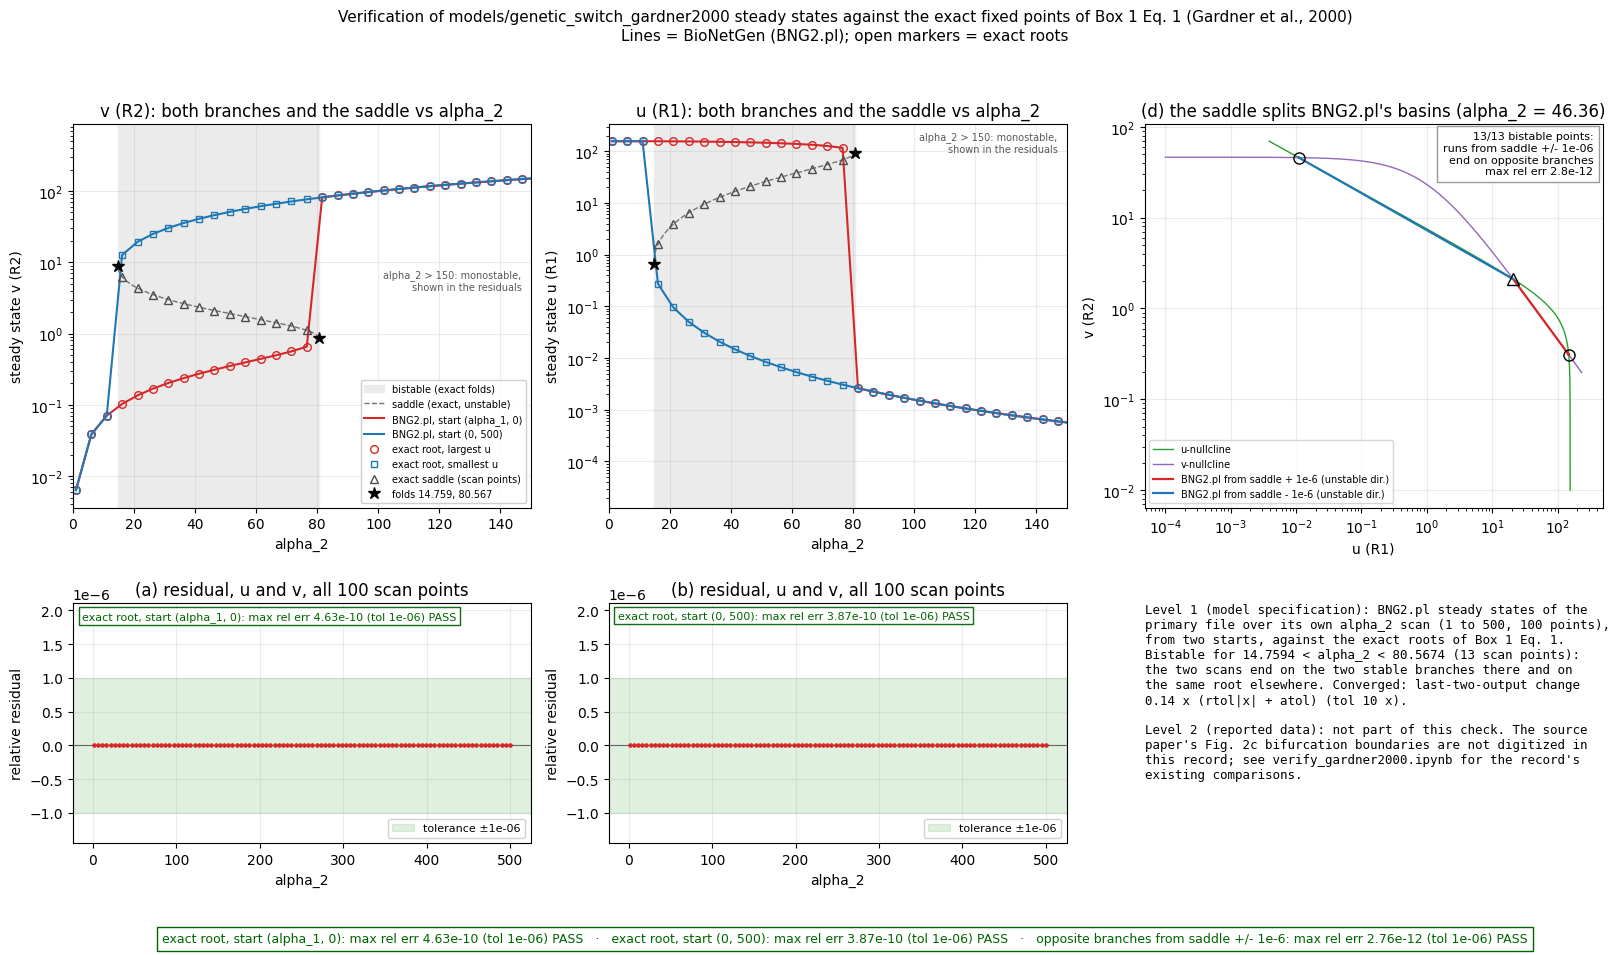

exact root, start (alpha_1, 0): max rel err 4.63e-10 (tol 1e-06) PASS
exact root, start (0, 500): max rel err 3.87e-10 (tol 1e-06) PASS
opposite branches from saddle +/- 1e-6: max rel err 2.76e-12 (tol 1e-06) PASS


In [7]:
dense = np.linspace(A2_MIN, A2_MAX, 4000)
dense = np.sort(np.concatenate([dense, np.linspace(A2_LO, A2_HI, 1500)[1:-1]]))
branch = {"u": [], "s": [], "v": []}
for a2 in dense:
    r = fixed_points(a2)
    branch["u"].append((a2, r[-1][0], r[-1][1]))
    branch["v"].append((a2, r[0][0], r[0][1]))
    if len(r) == 3:
        branch["s"].append((a2, r[1][0], r[1][1]))
branch = {k: np.array(v) for k, v in branch.items()}

fig = plt.figure(figsize=(17, 9.6))
gs = fig.add_gridspec(2, 3, height_ratios=[1.6, 1.0])
for col, (idx, name) in enumerate(((1, "v (R2)"), (0, "u (R1)"))):
    ax = fig.add_subplot(gs[0, col])
    ax.axvspan(A2_LO, A2_HI, color="0.92", zorder=0, label="bistable (exact folds)")
    ax.plot(branch["s"][:, 0], branch["s"][:, 1 + idx], "--", color="0.45", lw=1.0,
            label="saddle (exact, unstable)")
    ax.plot(grid, scans[START_U][:, idx], "-", color="C3", lw=1.5,
            label="BNG2.pl, start (alpha_1, 0)")
    ax.plot(grid, scans[START_V][:, idx], "-", color="C0", lw=1.5, label="BNG2.pl, start (0, 500)")
    ax.plot(grid, target[START_U][:, idx], "o", mfc="none", mec="C3", ms=5.5, ls="none",
            label="exact root, largest u")
    ax.plot(grid, target[START_V][:, idx], "s", mfc="none", mec="C0", ms=5, ls="none",
            label="exact root, smallest u")
    sad = np.array([roots[k][1][idx] for k in np.flatnonzero(bistable)])
    ax.plot(grid[bistable], sad, "^", mfc="none", mec="0.3", ms=5.5, ls="none",
            label="exact saddle (scan points)")
    ax.plot([A2_LO, A2_HI], [(U_LO, V_LO)[idx], (U_HI, V_HI)[idx]], "*", color="k",
            ms=9, label=f"folds {A2_LO:.3f}, {A2_HI:.3f}")
    ax.set(yscale="log", xlabel="alpha_2", ylabel=f"steady state {name}",
           title=f"{name}: both branches and the saddle vs alpha_2", xlim=(0, 150 if col else 150))
    ax.grid(alpha=0.25)
    if col == 0:
        ax.legend(fontsize=7, loc="lower right", framealpha=0.95)
    ax.text(0.98, 0.98 if col else 0.62, "alpha_2 > 150: monostable,\nshown in the residuals",
            transform=ax.transAxes, fontsize=7, ha="right", va="top", color="0.35")

# phase plane at one bistable scan point
k0 = int(np.flatnonzero(bistable)[len(np.flatnonzero(bistable)) // 2])
ax = fig.add_subplot(gs[0, 2])
uu = np.logspace(-4, np.log10(A1 * 1.5), 600)
vv = np.logspace(-2, np.log10(grid[k0] * 1.5), 600)
ax.plot(A1 / (KDEG * (1 + vv**BETA)), vv, "-", color="C2", lw=1, label="u-nullcline")
ax.plot(uu, grid[k0] / (KDEG * (1 + uu**GAMMA)), "-", color="C4", lw=1, label="v-nullcline")
for tag, c in (("p", "C3"), ("m", "C0")):
    tr = sep_traj[k0, tag]
    ax.plot(tr[:, 1], tr[:, 2], "-", color=c, lw=1.6, label=f"BNG2.pl from saddle {'+' if tag == 'p' else '-'} 1e-6 (unstable dir.)")
for j, (u, v, ev) in enumerate(roots[k0]):
    ax.plot(u, v, "o" if ev.real.max() < 0 else "^", mfc="none", mec="k", ms=8, ls="none")
ax.set(xscale="log", yscale="log", xlabel="u (R1)", ylabel="v (R2)",
       title=f"(d) the saddle splits BNG2.pl's basins (alpha_2 = {grid[k0]:.2f})")
ax.legend(fontsize=7, loc="lower left")
ax.text(0.98, 0.98, f"{len(sep_starts)}/{len(sep_starts)} bistable points:\nruns from saddle +/- "
        f"{EPS_SADDLE:g}\nend on opposite branches\nmax rel err {sep_err.max():.1e}",
        transform=ax.transAxes, fontsize=8, ha="right", va="top",
        bbox={"fc": "white", "ec": "0.6"})
ax.grid(alpha=0.25)

metrics = []
for col, (start, label) in enumerate(((START_U, "exact root, start (alpha_1, 0)"),
                                      (START_V, "exact root, start (0, 500)"))):
    ax = fig.add_subplot(gs[1, col])
    comp = Comparison(label, target[start].ravel(), tol=TOL_SS, floor=1e-300)
    xs = np.repeat(grid, 2)
    residual_axis(ax, xs, scans[start].ravel(), comp, xlabel="alpha_2",
                  title=f"({'a' if start == START_U else 'b'}) residual, u and v, all 100 scan points")
    metrics.append(summarize(xs, scans[start].ravel(), comp))
sep_comp = Comparison("opposite branches from saddle +/- 1e-6", np.ones(sep_err.size), tol=TOL_SS)
sep_metric = summarize(None, np.ones(sep_err.size) + sep_err, sep_comp)
metrics.append(sep_metric)

ax = fig.add_subplot(gs[1, 2])
ax.axis("off")
ax.text(0.0, 1.0,
        "Level 1 (model specification): BNG2.pl steady states of the\n"
        "primary file over its own alpha_2 scan (1 to 500, 100 points),\n"
        "from two starts, against the exact roots of Box 1 Eq. 1.\n"
        f"Bistable for {A2_LO:.4f} < alpha_2 < {A2_HI:.4f} ({bistable.sum()} scan points):\n"
        "the two scans end on the two stable branches there and on\n"
        "the same root elsewhere. Converged: last-two-output change\n"
        f"{changes.max():.2f} x (rtol|x| + atol) (tol {TOL_CONVERGED:g} x).\n\n"
        "Level 2 (reported data): not part of this check. The source\n"
        "paper's Fig. 2c bifurcation boundaries are not digitized in\n"
        "this record; see verify_gardner2000.ipynb for the record's\n"
        "existing comparisons.",
        va="top", fontsize=9, family="monospace")

fig.suptitle("Verification of models/genetic_switch_gardner2000 steady states against the exact "
             "fixed points of Box 1 Eq. 1 (Gardner et al., 2000)\n"
             "Lines = BioNetGen (BNG2.pl); open markers = exact roots", fontsize=11)
fig.tight_layout(rect=(0, 0.05, 1, 0.95))
ok = verdict_footer(fig, metrics)
assert ok
fig.savefig("verify_gardner2000_steady_state.png", dpi=150, bbox_inches="tight")
plt.show()
for m in metrics:
    print(m.line())